In [2]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
 
# Carrega os atributos (X) e rótulos (y) com matrizes Numpy
X, y = load_breast_cancer(return_X_y=True)
X, y = np.asarray(X), np.asarray(y)
nomes_classes = ["malignant", "benign"]
 
# Divisão (70% treino , 30% teste)
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)
 
print(f"Total de instâncias para Treino: {len(y_treino)}")
print(f"Total de instâncias para Teste: {len(y_teste)}")

Total de instâncias para Treino: 398
Total de instâncias para Teste: 171


In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron

#Definição do Pipeline: Padronização + Perceptron
pipe_perceptron = Pipeline([
    ("escalonador", StandardScaler()),
    ("classificador", Perceptron(max_iter=1000, random_state=42))
])

#Treinamento
pipe_perceptron.fit(X_treino, y_treino)

#Avaliação direta da acurácia
acuracia_perceptron = pipe_perceptron.score(X_teste, y_teste)
print(f"Acurácia do Pipeline Perceptron: {acuracia_perceptron:.2%}")

Acurácia do Pipeline Perceptron: 98.25%


In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier

#Criação direta com make_pipeline
pipe_knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

#Treinamento
pipe_knn.fit(X_treino, y_treino)

#Avaliação direta da acurácia
acuracia_knn = pipe_knn.score(X_teste, y_teste)
print(f"Acuracia do Pipeline KNN (K=5): {acuracia_knn:.2%}")

Acuracia do Pipeline KNN (K=5): 95.91%


In [8]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

pipelines = {
    "Pipeline Perceptron": pipe_perceptron, 
    "Pipeline KNN (K=5)": pipe_knn
}

resultados = []

for nome, pipe in pipelines.items():
    y_pred = pipe.predict(X_teste)

    resultados.append({
        "Modelo / Pipeline": nome,
        "Acurácia": accuracy_score(y_teste, y_pred),
        "Precisão": precision_score(y_teste, y_pred, zero_division=0),
        "Recall": recall_score(y_teste, y_pred, zero_division=0),
        "F1-Score": f1_score(y_teste, y_pred, zero_division=0)
    })

df_resultados = pd.DataFrame(resultados)
print(df_resultados.to_string(index=False))

  Modelo / Pipeline  Acurácia  Precisão   Recall  F1-Score
Pipeline Perceptron  0.982456  0.981481 0.990654  0.986047
 Pipeline KNN (K=5)  0.959064  0.938596 1.000000  0.968326


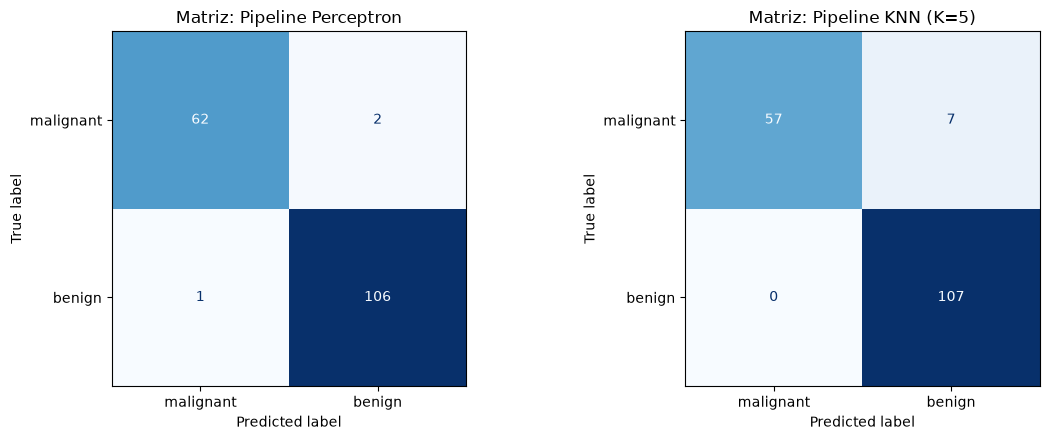

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
 
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
 
for i, (nome, pipe) in  enumerate(pipelines.items()):
    ConfusionMatrixDisplay.from_estimator(
        pipe,
        X_teste,
        y_teste,
        display_labels=nomes_classes,
        cmap="Blues",
        ax=axes[i],
        colorbar=False
    )
    axes[i].set_title(f"Matriz: {nome}")
    axes[i].grid(False)
 
plt.tight_layout()
plt.show()

In [11]:
from sklearn.metrics import classification_report

for nome, pipe in pipelines.items():
    y_pred = pipe.predict(X_teste)
    print("=" * 65)
    print(f"Relatorio de Desempenho: {nome}")
    print("=" * 65)
    print(classification_report(y_teste, y_pred, target_names=nomes_classes, zero_division=0))
    print()

Relatorio de Desempenho: Pipeline Perceptron
              precision    recall  f1-score   support

   malignant       0.98      0.97      0.98        64
      benign       0.98      0.99      0.99       107

    accuracy                           0.98       171
   macro avg       0.98      0.98      0.98       171
weighted avg       0.98      0.98      0.98       171


Relatorio de Desempenho: Pipeline KNN (K=5)
              precision    recall  f1-score   support

   malignant       1.00      0.89      0.94        64
      benign       0.94      1.00      0.97       107

    accuracy                           0.96       171
   macro avg       0.97      0.95      0.96       171
weighted avg       0.96      0.96      0.96       171


